In [1]:
! pip install pandas matplotlib scikit-learn seaborn


[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
'''
eda.ipynb

Modulo 2
'''

import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

print(' Bibliotecas carregadas')

 Bibliotecas carregadas


## Carregamento e Visão Geral

In [3]:
df = pd.read_csv('processed_lisboa_porto_air_quality.csv', sep=';')

print('\nPrimeiras linhas')
print(df.head())

print('\n Shape')
print(f'{df.shape[0]} registos, {df.shape[1]} colunas')

print('\nTipos de dados')
print(df.dtypes)

print('\n Estatísticas descritivas')
print(df.describe())

print('\nMissing values')
missing = df.isnull().sum()
missing = missing[missing > 0]
if missing.empty:
    print('Sem valores em falta.')
else:
    print(missing)

print('\nDistribuição da label (air_quality_good)')
print(df['air_quality_good'].value_counts())
print(f'  Proporção positiva: {df["air_quality_good"].mean():.2%}')

# tratamento de valores em falta
# qualquer linha com menos de 9 colunas preenchidas vai ser apagada
df = df.dropna(axis= 0, thresh=9)


Primeiras linhas
     city        datetime    CO    NO2     O3   PM10  PM2.5   SO2  \
0  Lisboa  05/09/25 01:00  0.96  25.20  84.09  11.82   9.12  6.75   
1  Lisboa  05/09/25 02:00  0.75  26.40  86.20  13.24   8.87  5.11   
2  Lisboa  05/09/25 03:00  0.87  25.16  74.41  15.18  10.84  5.76   
3  Lisboa  05/09/25 04:00  0.51  13.59  68.57  17.48  13.14  5.03   
4  Lisboa  05/09/25 05:00  0.61  15.89  78.79  14.70  13.68  6.20   

   temperature_c  humidity_percent  pressure_hpa  wind_speed_kmh  \
0           18.9              82.0        1018.5            16.2   
1           18.8              80.0        1018.3            15.5   
2           18.6              79.0        1017.4            11.5   
3           18.3              77.0        1017.2            11.3   
4           18.6              72.0        1016.8             9.4   

   wind_direction_deg  precipitation_mm  C6H6  NMHC  NOx  air_quality_good  \
0               357.0               0.0   NaN   NaN  NaN              True   
1 

                CO          NO2           O3         PM10        PM2.5  \
count  9116.000000  9157.000000  1442.000000  1442.000000  1442.000000   
mean      1.971439    99.959433    69.301706    21.614896    15.138800   
std       1.408473    54.052344    16.780429     9.428184     6.889596   
min       0.100000     2.000000    28.220000     1.840000     0.100000   
25%       0.940000    57.120000    56.552500    13.952500     9.650000   
50%       1.600000    98.000000    69.205000    20.110000    14.080000   
75%       2.600000   134.000000    81.310000    28.020000    19.940000   
max      11.900000   340.000000   114.680000    58.570000    38.750000   

               SO2  temperature_c  humidity_percent  pressure_hpa  \
count  1442.000000   10433.000000      10433.000000   1442.000000   
mean      6.453259      18.471341         51.978213   1019.587864   
std       3.050010       8.327228         18.949539      3.062214   
min       0.100000      -1.900000          9.200000   100

## Boxplots dos Poluentes por Qualidade do Ar

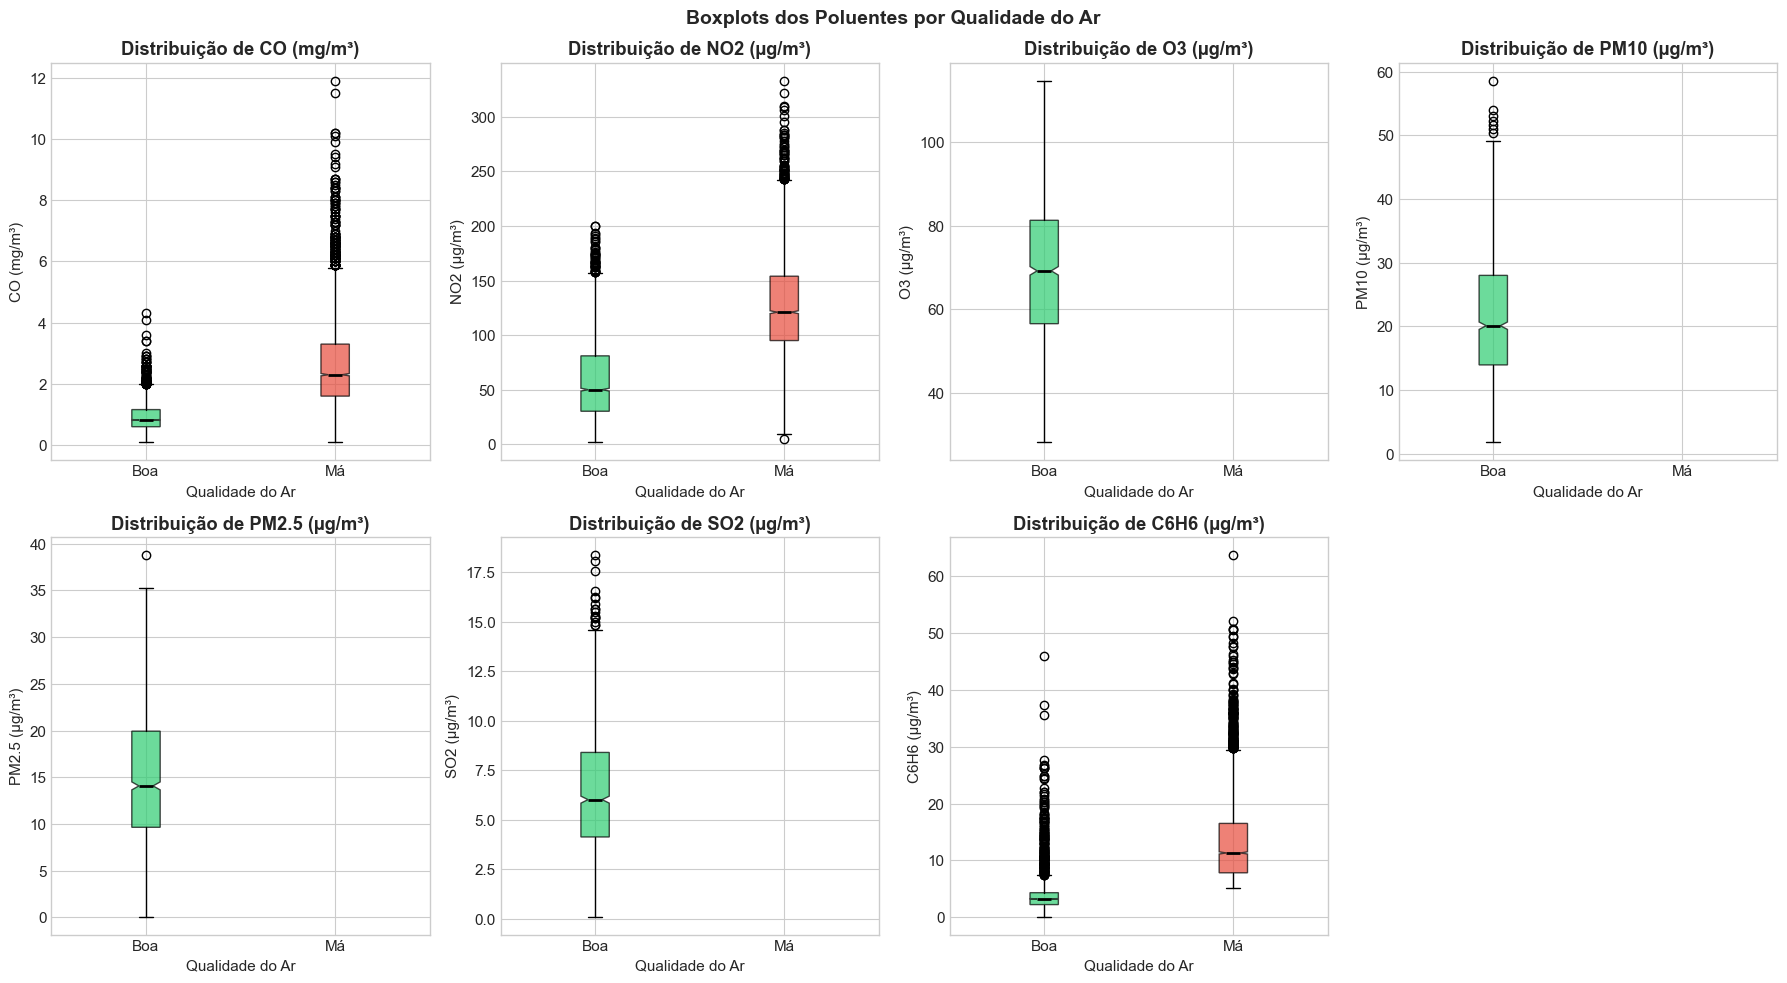

Conseguimos observar que alguns poluentes não possuem dados quando a qualidade do ar é má (Ozono,PM10,PM2.5)
Mas recolhemos informação como:
 Maiores concentrações de Monoxido de Carbono estão associadas á má qualidade do ar.
 Maiores concentrações de Dióxido de Nitrogénio estão associadas á má qualidade do ar.
 Maiores concentrações de Benzeno estão associadas á má qualidade do ar.


In [4]:
# variáveis independentes + labels
sinais = ['CO', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'C6H6']
labels_sinais = ['CO (mg/m³)', 'NO2 (µg/m³)', 'O3 (µg/m³)', 'PM10 (µg/m³)',
                 'PM2.5 (µg/m³)', 'SO2 (µg/m³)', 'C6H6 (µg/m³)']

# variavel dependente (Qualidade do ar)
estados_ordem = [True, False]
cores_estados  = {True: '#2ecc71', False: '#e74c3c'}
labels_estados = {True: 'Boa', False: 'Má'}

# criação de varios subplots que analisam uma variavel consoante a qualidade do ar está boa ou má
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, sinal, label in zip(axes.flat, sinais, labels_sinais):
    data_plot = [df[df['air_quality_good'] == e][sinal].dropna() for e in estados_ordem]
    bp = ax.boxplot(data_plot, labels=['Boa', 'Má'], patch_artist=True, notch=True,
                    medianprops=dict(color='black', linewidth=2))
    for patch, estado in zip(bp['boxes'], estados_ordem):
        patch.set_facecolor(cores_estados[estado])
        patch.set_alpha(0.7)
    ax.set_title(f'Distribuição de {label}', fontweight='bold')
    ax.set_xlabel('Qualidade do Ar')
    ax.set_ylabel(label)

# Esconde o último subplot (temos 7 sinais em 8 espaços)
axes.flat[-1].set_visible(False)


plt.suptitle('Boxplots dos Poluentes por Qualidade do Ar', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('boxplots_poluentes.png', dpi=150, bbox_inches='tight')
plt.show()

print('Conseguimos observar que alguns poluentes não possuem dados quando a qualidade do ar é má (Ozono,PM10,PM2.5)')
print('Mas recolhemos informação como:')
print(' Maiores concentrações de Monoxido de Carbono estão associadas á má qualidade do ar.')
print(' Maiores concentrações de Dióxido de Nitrogénio estão associadas á má qualidade do ar.')
print(' Maiores concentrações de Benzeno estão associadas á má qualidade do ar.')


## Correlação e Scatter

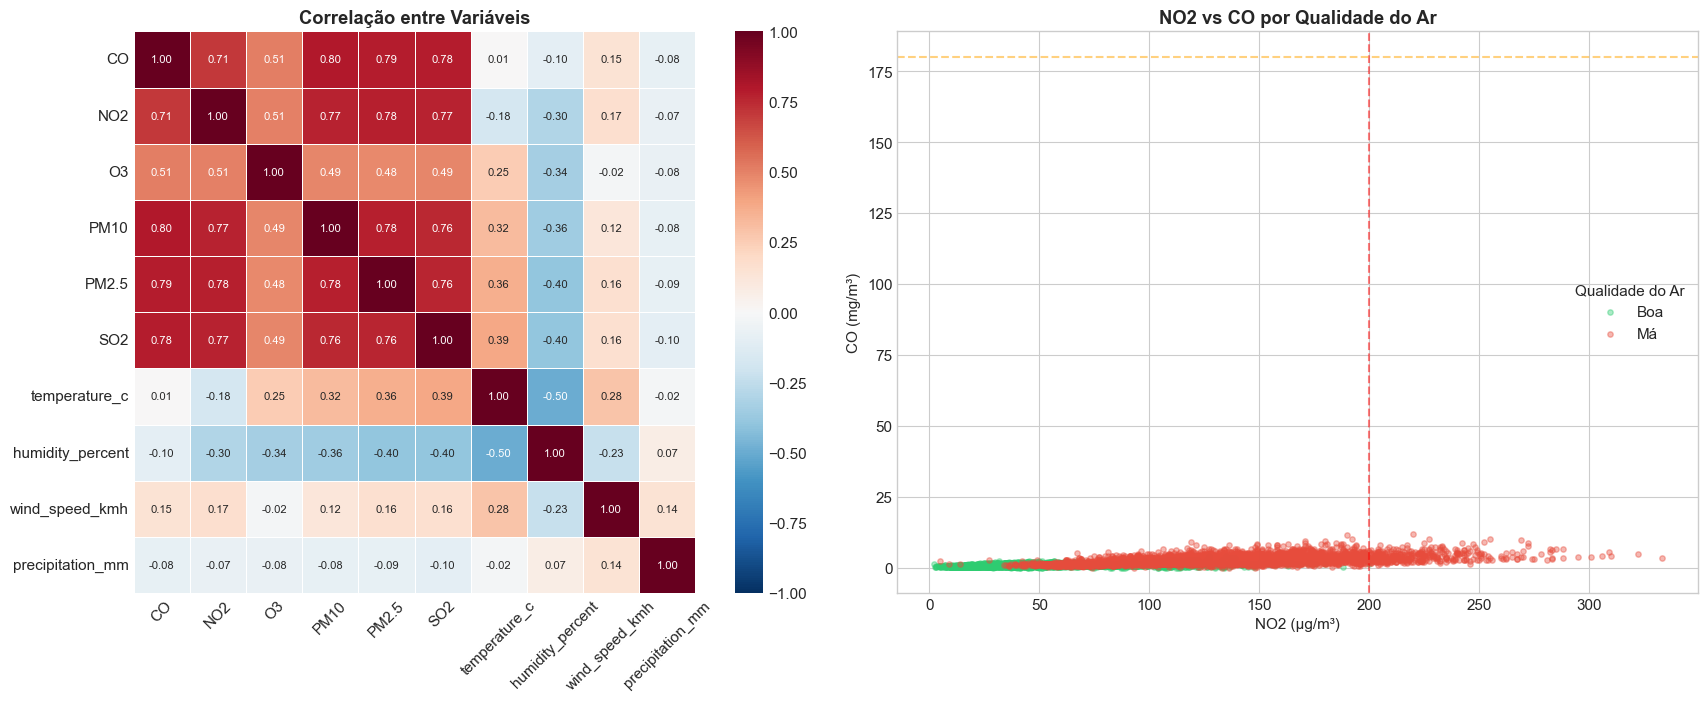

In [5]:
# variáveis usadas
sinais_corr = ['CO', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
               'temperature_c', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm']

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Heatmap de correlação entre variáveis
corr = df[sinais_corr].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=axes[0], vmin=-1, vmax=1,
            annot_kws={"size": 8})
axes[0].set_title('Correlação entre Variáveis', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# Scatter de NO2 vs CO colorido por qualidade do ar
for estado in estados_ordem:
    mask_e = df['air_quality_good'] == estado
    axes[1].scatter(df[mask_e]['NO2'], df[mask_e]['CO'],
                    c=cores_estados[estado], label=labels_estados[estado],
                    alpha=0.4, s=15)
axes[1].set_xlabel('NO2 (µg/m³)')
axes[1].set_ylabel('CO (mg/m³)')
axes[1].set_title('NO2 vs CO por Qualidade do Ar', fontweight='bold')
axes[1].legend(title='Qualidade do Ar')
axes[1].axvline(200, color='red', linestyle='--', alpha=0.5, label='Limiar NO2')
axes[1].axhline(180, color='orange', linestyle='--', alpha=0.5, label='Limiar CO')

plt.tight_layout()
plt.savefig('correlacao_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## Histogramas das Variáveis Principais

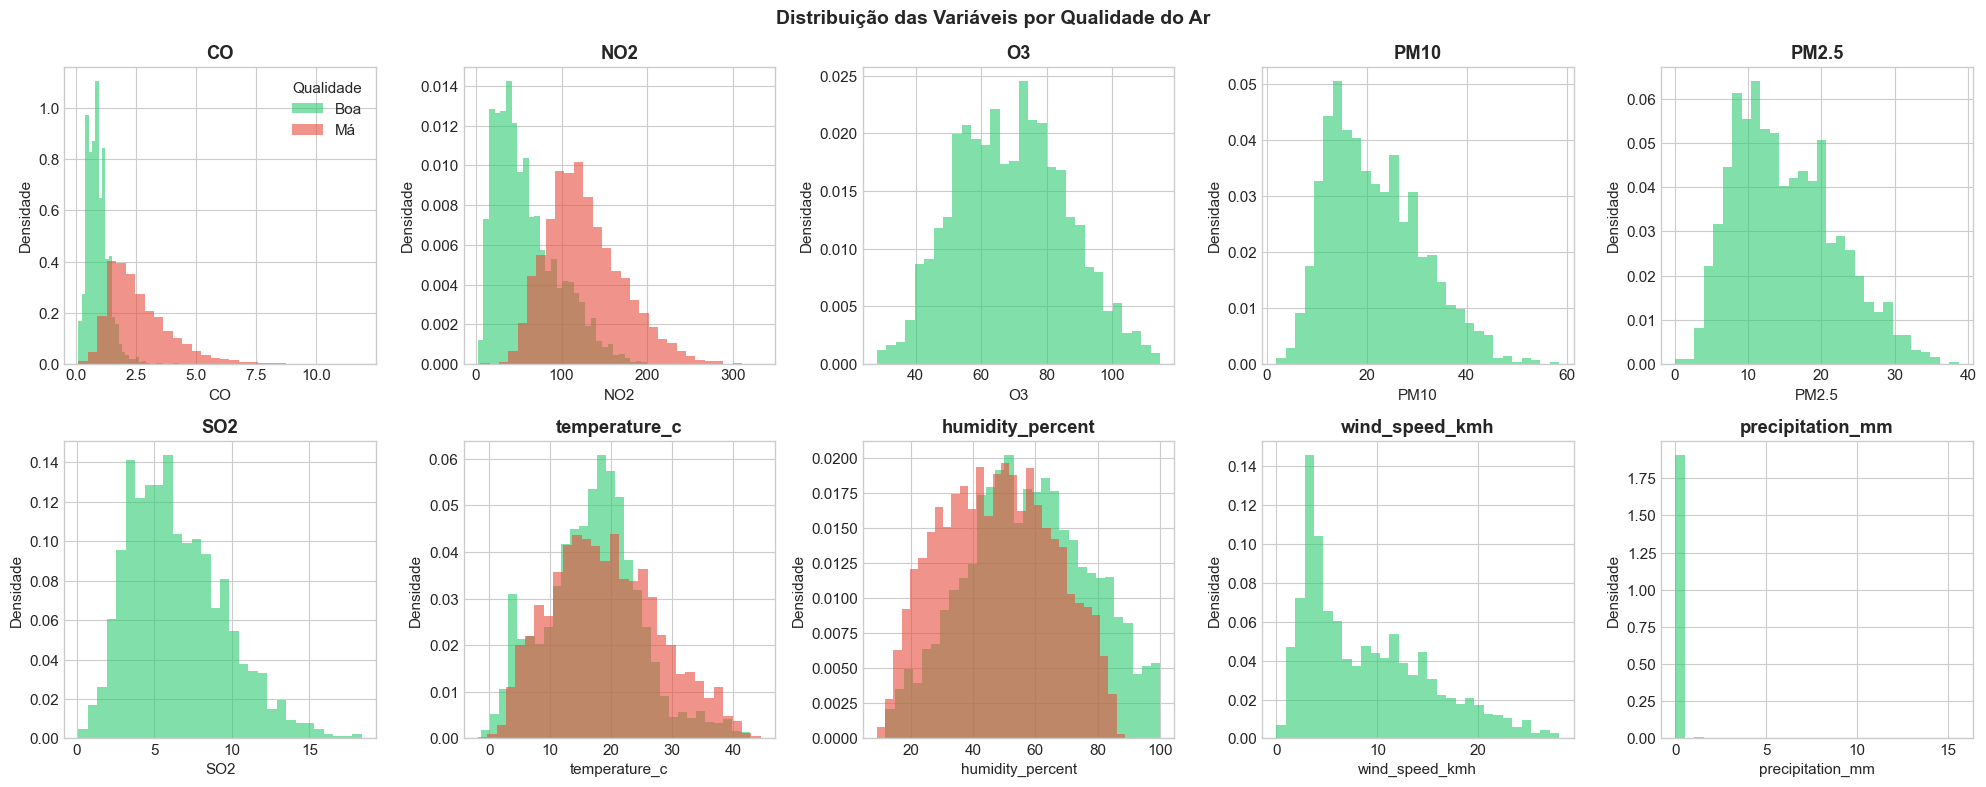

In [6]:
#histograma entre variáveis e qualidade do ar

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for ax, sinal in zip(axes.flat, sinais_corr):
    for estado in estados_ordem:
        mask_e = df['air_quality_good'] == estado
        ax.hist(df[mask_e][sinal].dropna(), bins=30, alpha=0.6,
                color=cores_estados[estado], label=labels_estados[estado], density=True)
    ax.set_title(sinal, fontweight='bold')
    ax.set_xlabel(sinal)
    ax.set_ylabel('Densidade')

axes[0][0].legend(title='Qualidade')
plt.suptitle('Distribuição das Variáveis por Qualidade do Ar', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('histogramas.png', dpi=150, bbox_inches='tight')
plt.show()

## PCA — Separabilidade das Classes

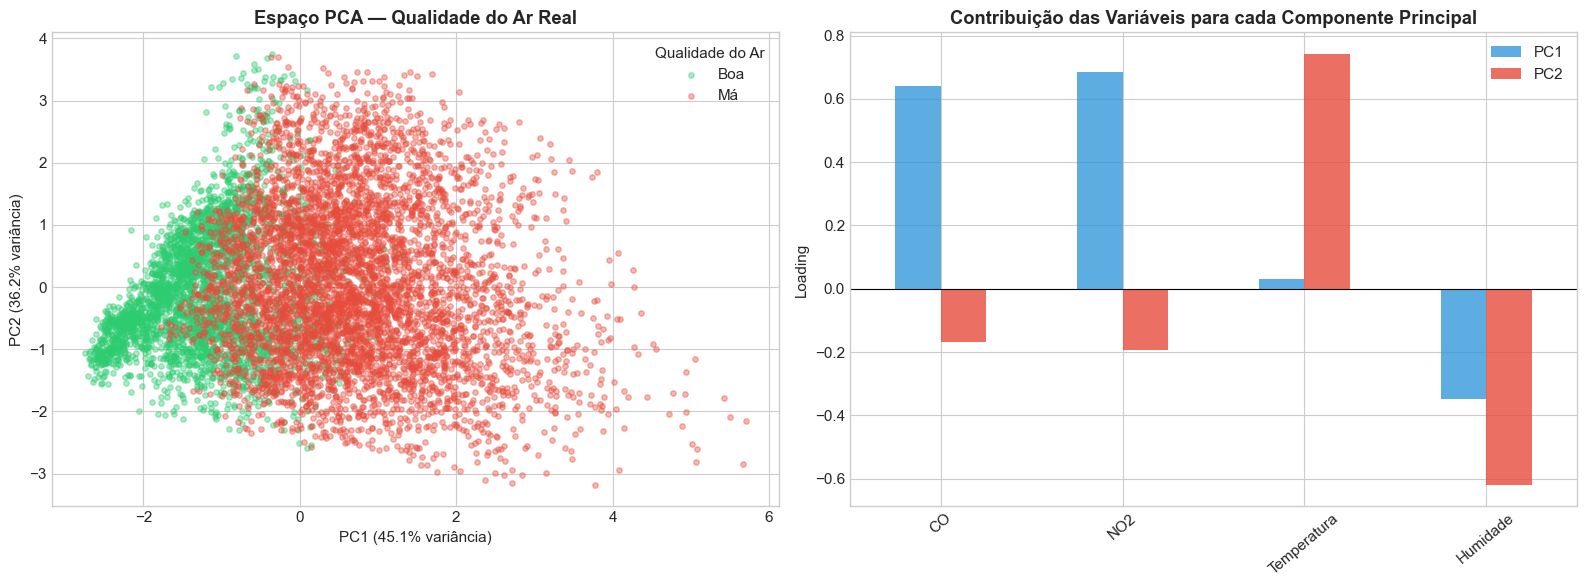

 PCA: PC1+PC2 explicam 81.3% da variância total.

 EDA concluída — gráficos guardados em boxplots_poluentes.png, correlacao_scatter.png, histogramas.png, pca.png


In [7]:
# apenas as variáveis com instâncias de qualidade do ar boa e má

sinais_pca    = ['CO', 'NO2',
                 'temperature_c', 'humidity_percent']
labels_pca    = ['CO', 'NO2',
                 'Temperatura', 'Humidade']

#retirar  vazios
df_pca = df[sinais_pca].dropna()
idx    = df_pca.index

#Normalisação dos valores
scaler_pca = StandardScaler()
X_scaled   = scaler_pca.fit_transform(df_pca)

# aplicação do pca
pca  = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA colorido por qualidade do ar
for estado in estados_ordem:
    mask_e = df.loc[idx, 'air_quality_good'] == estado
    axes[0].scatter(X_2d[mask_e, 0], X_2d[mask_e, 1],
                    c=cores_estados[estado], label=labels_estados[estado],
                    alpha=0.4, s=15)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variância)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variância)')
axes[0].set_title('Espaço PCA — Qualidade do Ar Real', fontweight='bold')
axes[0].legend(title='Qualidade do Ar')

# Contribuição de cada variável para os componentes
loadings = pd.DataFrame(pca.components_.T, index=labels_pca, columns=['PC1', 'PC2'])
loadings.plot(kind='bar', ax=axes[1], color=['#3498db', '#e74c3c'], alpha=0.8)
axes[1].set_title('Contribuição das Variáveis para cada Componente Principal', fontweight='bold')
axes[1].set_ylabel('Loading')
axes[1].tick_params(axis='x', rotation=40)
axes[1].axhline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig('pca.png', dpi=150, bbox_inches='tight')
plt.show()

print(f' PCA: PC1+PC2 explicam {sum(pca.explained_variance_ratio_[:2]):.1%} da variância total.')

print('\n EDA concluída — gráficos guardados em boxplots_poluentes.png, correlacao_scatter.png, histogramas.png, pca.png')